# From Corporate Disclosures to Diversified Thematic Portfolios
## LLM-guided critical-minerals discovery with holdings-based asset embeddings

**Presentation summary — completed through August 2026**

This project asks whether an evidence-grounded language model can define the direct corporate footprint of an economic theme and whether holdings-based asset embeddings can broaden those seeds into a more diversified portfolio without losing the theme.

The central result is not that embeddings mechanically beat a concentrated minerals benchmark. The result is that they converted a concentrated, disclosure-led theme into portfolios with **meaningful critical-minerals sensitivity, materially lower volatility, and smaller drawdowns**. The strongest long-only hybrid returned **69.84%** from June 2024 through August 2026, versus **84.84%** for the minerals benchmark and **49.25%** for the S&P 500, while taking substantially less risk than the minerals benchmark.

## 1. Starting question and final answer

The experiment began with a practical portfolio-construction question:

> Can a language model identify firms positioned to benefit or suffer under a defined critical-minerals scenario, and can asset embeddings discover additional related firms and turn those signals into a diversified thematic portfolio?

The answer is **yes, with qualifications**:

- The LLM produced evidence-backed positive and negative seeds from point-in-time SEC filings.
- Embeddings expanded those seeds through institutional co-holding relationships rather than through additional textual inference.
- The embedding and hybrid portfolios retained statistically significant critical-minerals exposure after controlling for the market.
- Their primary benefit was **risk-managed thematic exposure**, not universal raw-return dominance.
- A single main formation vintage and a post-primary persistence extension do not establish persistent abnormal return.

The work proceeded in two stages: a smaller quarterly pilot developed the workflow, and a point-in-time S&P 500 experiment supplied the main validation.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT=Path.cwd()
if ROOT.name!='sp500_critical_minerals':
    candidate=Path('/Users/harmandeep/Desktop/Projects/Asset_Embeddings/geopolitical_exposure/sp500_critical_minerals')
    if candidate.exists(): ROOT=candidate

BLUE='#0072B2'; ORANGE='#D55E00'; GREEN='#009E73'; PURPLE='#CC79A7'; GREY='#777777'; SKY='#56B4E9'
plt.rcParams.update({'figure.dpi':120,'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.18,'font.size':11})
pd.set_option('display.max_colwidth',90)

def pct(x): return f'{100*x:.2f}%'
def label_bars(ax,fmt='{:.1f}',pad=3):
    for container in ax.containers:
        ax.bar_label(container,fmt=fmt,padding=pad,fontsize=9)

print('Evidence root:',ROOT)

Matplotlib is building the font cache; this may take a moment.


Evidence root: /Users/harmandeep/Desktop/Projects/Asset_Embeddings/geopolitical_exposure/sp500_critical_minerals


## 2. Why critical-minerals exposure required a scenario

A firm is not permanently “positive” or “negative” with respect to critical minerals. Direction depends on what changes economically. The frozen scenario was:

> **A sustained increase in strategic demand and policy support for critical minerals, accompanied by Western supply-chain security initiatives and supply-chain reorientation.**

Positive exposure could arise through extraction, reserves, refining, recycling, substitution technology, producer services, or policy-supported investment. Negative exposure could arise through higher input costs, constrained sourcing, sanctions, trade restrictions, bottlenecks, or limited substitution.

This definition separates **economic direction** from simple keyword frequency. A company mentioning lithium because it faces an input shortage should not receive the same sign as a lithium producer expecting higher demand.

**Design source:** [12A — Point-in-Time Universe](12A_SP500_Point_in_Time_Universe.ipynb), [12C — Blinded Prompt Calibration](12C_Blinded_Prompt_Calibration.ipynb), and `config/critical_minerals_extraction_prompt_v2.md`.

## 3. Research sequence and information safeguards

| Stage | Information opened | Information deliberately unavailable |
|---|---|---|
| Universe | Historical S&P 500 membership, CRSP/Compustat identifiers, embedding coverage | SEC text, API labels, future returns |
| Corpus | Point-in-time 10-K/10-Q filings and retrieved passages | Embedding outcomes and future returns |
| Calibration | Fixed blinded document sample and structured extraction | Portfolio outcomes |
| Production extraction | Retrieved passages, frozen prompt/schema, exact evidence rules | Embeddings and future returns |
| Embedding propagation | Frozen LLM seeds and holdings embeddings | Forward returns |
| Locked evaluation | Frozen portfolios and pre-specified forward returns | No reselection permitted |
| Persistence study | Frozen 2024Q1 portfolios and later returns | Portfolio membership remained unchanged |

This ordering matters. Text labels and embedding thresholds were not chosen by searching for the best-performing stocks. Every major stage wrote hashes, manifests, and decision gates before the next information set was opened.

Stage,Count
Unique point-in-time filings,"2,080"
Retrieval/API queue,923
Valid document outputs,923
Exposure records,204
Positive seed firm-quarters,65
Negative seed firm-quarters,164


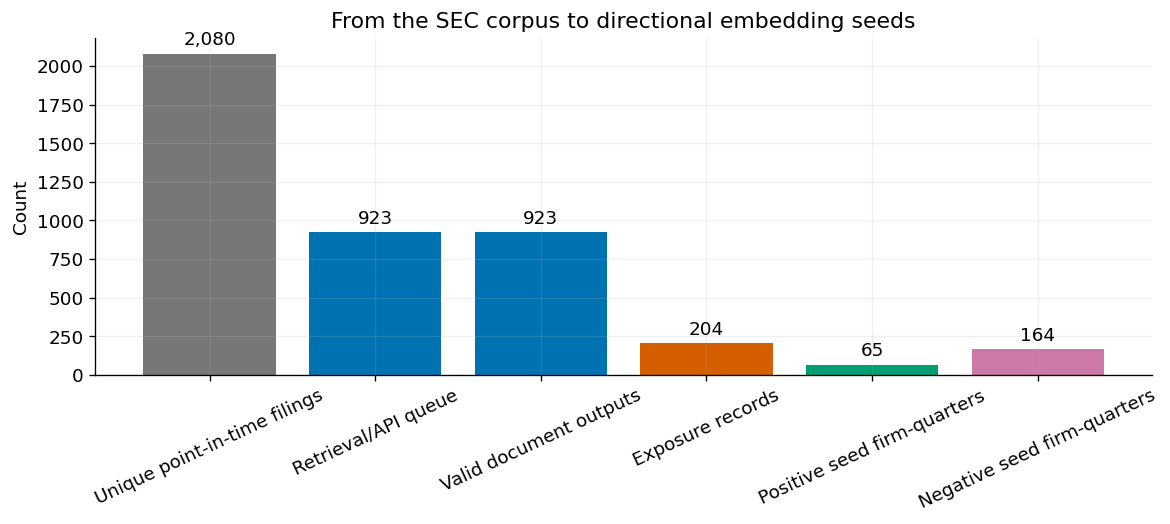

In [2]:
corpus=json.loads((ROOT/'manifests'/'corpus_manifest.json').read_text())
resolution=json.loads((ROOT/'resolved_extraction_v2_1'/'resolution_manifest.json').read_text())
aggregation=json.loads((ROOT/'quarterly_exposure_v1'/'aggregation_manifest.json').read_text())
funnel=pd.DataFrame({
    'Stage':['Unique point-in-time filings','Retrieval/API queue','Valid document outputs','Exposure records','Positive seed firm-quarters','Negative seed firm-quarters'],
    'Count':[corpus['unique_documents'],corpus['api_queue_documents'],resolution['valid_documents'],resolution['exposure_records'],aggregation['positive_seed_firm_quarters'],aggregation['negative_seed_firm_quarters']]
})
display(funnel.style.hide(axis='index').format({'Count':'{:,.0f}'}))
fig,ax=plt.subplots(figsize=(10,4.5));bars=ax.bar(funnel.Stage,funnel.Count,color=[GREY,BLUE,BLUE,ORANGE,GREEN,PURPLE])
ax.set_title('From the SEC corpus to directional embedding seeds');ax.set_ylabel('Count');ax.tick_params(axis='x',rotation=25)
ax.bar_label(bars,labels=[f'{v:,.0f}' for v in funnel.Count],padding=3)
plt.tight_layout();plt.show()

## 4. What the LLM did—and did not do

The LLM acted as an evidence-grounded analyst, not an autonomous portfolio manager. For each retrieved filing passage, it had to:

1. identify an allowed economic mechanism;
2. assign positive or negative direction under the frozen scenario;
3. distinguish direct, first-order indirect, and second-order indirect exposure;
4. assign exposure strength and confidence;
5. reproduce a contiguous source quotation; and
6. return a strict structured object with unchanged identifiers.

The production safeguard required exact quotations of no more than 60 words. If a qualifying quotation did not exist, the model had to omit the exposure rather than reconstruct one. Six quarantined outputs were resolved under a frozen audit contract without changing the original responses or making additional API calls.

The LLM therefore supplied **documented directional seeds**. It did not observe future stock returns, and it did not construct the final portfolio.

**Implementation source:** [12D — Production Extraction](12D_SP500_Production_Extraction.ipynb), [12D2 — Quarantine Resolution](12D2_Quarantined_Response_Resolution.ipynb), and `src/production_extraction.py`.

## 5. What the embeddings added

The asset embeddings come from institutional portfolio co-holdings. Firms frequently held in similar portfolios occupy nearby positions in the embedding space.

The LLM-labelled firms supplied direction:

- positive text seeds defined the beneficiary side;
- negative text seeds defined the adverse side; and
- every other eligible firm received a score according to its relative proximity to those seed sets.

This is a distinct information channel. The embeddings do not read filings or infer supply-chain prose. They test whether institutional ownership geometry links the documented seeds to firms that may share related economic exposures.

Three principal signals were retained:

| Signal | Definition | Purpose |
|---|---|---|
| **LLM-only** | Direct evidence extracted from the firm’s own filings | Disclosure benchmark |
| **Embedding-only** | Relative proximity to positive and negative LLM seeds | Incremental discovery |
| **Hybrid** | Frozen combination of text and embedding scores | Complementary information |

**Embedding source:** [12F — Embedding Propagation and Placebos](12F_Embedding_Propagation_and_Placebos.ipynb).

## 6. The first locked return test was weak

The first outcome test used four pre-defined three-month windows. It did not support a simple claim that embedding-selected portfolios immediately outperform. Results varied substantially by quarter, and the initial 2024Q1 long–short portfolios were negative.

That failure changed the next question. Instead of treating short-window return as the only validation, the project tested whether the signals measured a real thematic exposure and whether embeddings improved diversification.

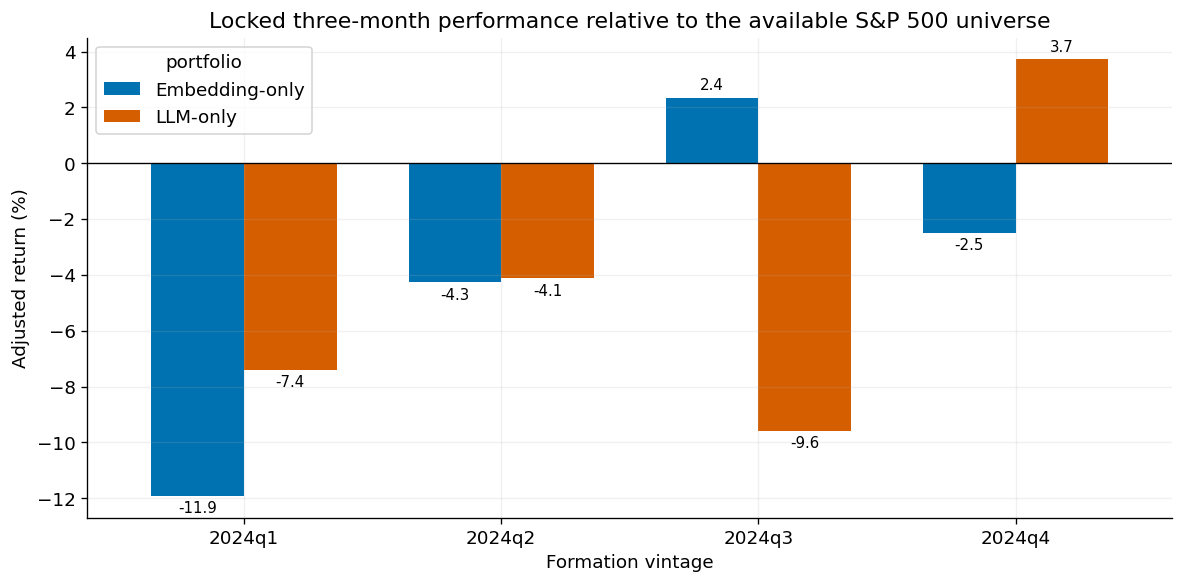

portfolio,Embedding-only,LLM-only
vintage,,
2024q1,-11.92%,-7.40%
2024q2,-4.27%,-4.12%
2024q3,2.35%,-9.59%
2024q4,-2.49%,3.72%


In [3]:
early=pd.read_parquet(ROOT/'forward_performance_v1'/'primary_portfolio_results.parquet')
piv=early.pivot(index='vintage',columns='portfolio',values='available_universe_adjusted_return')*100
piv=piv.rename(columns={'embedding_only_primary':'Embedding-only','llm_only_common_support':'LLM-only'})
ax=piv.plot(kind='bar',figsize=(10,5),color=[BLUE,ORANGE],width=.72)
ax.axhline(0,color='black',lw=.8);ax.set_title('Locked three-month performance relative to the available S&P 500 universe')
ax.set_ylabel('Adjusted return (%)');ax.set_xlabel('Formation vintage');ax.tick_params(axis='x',rotation=0);label_bars(ax,'%.1f')
plt.tight_layout();plt.show()
display((piv/100).style.format('{:.2%}'))

## 7. The thematic-beta test produced a second qualification

Text, embedding, and hybrid scores were compared with firms’ subsequent sensitivity to an investable critical-minerals factor. Rank correlations were sometimes positive—particularly in early vintages—but nested out-of-sample models did **not** show stable incremental prediction beyond conventional baseline variables.

This means the scores should not be described as a consistently superior firm-level thematic-beta forecasting model. The more defensible application became portfolio construction: can the embeddings distribute the theme across more firms and improve its risk profile?

**Source:** [14A — Factor Construction](14A_Critical_Minerals_Factor_Construction.ipynb), [14B — Firm Betas](14B_Firm_Thematic_Beta_Estimation.ipynb), and [14C — Score Validation](14C_Exposure_Scores_vs_Thematic_Beta.ipynb).

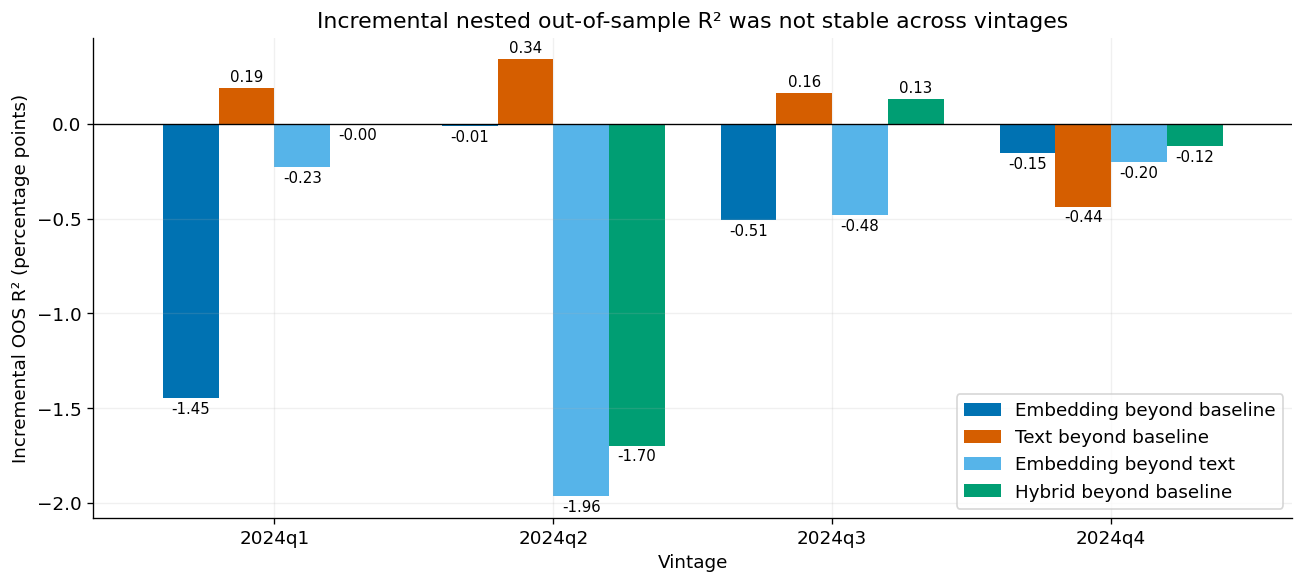

In [4]:
inc=pd.read_parquet(ROOT/'thematic_beta_prediction_v1'/'incremental_oos_r2.parquet').set_index('vintage')*100
inc=inc.rename(columns={'embedding_beyond_baseline':'Embedding beyond baseline','text_beyond_baseline':'Text beyond baseline','embedding_beyond_text':'Embedding beyond text','hybrid_beyond_baseline':'Hybrid beyond baseline'})
ax=inc.plot(kind='bar',figsize=(11,5),color=[BLUE,ORANGE,SKY,GREEN],width=.8)
ax.axhline(0,color='black',lw=.8);ax.set_title('Incremental nested out-of-sample R² was not stable across vintages')
ax.set_ylabel('Incremental OOS R² (percentage points)');ax.set_xlabel('Vintage');ax.tick_params(axis='x',rotation=0);label_bars(ax,'%.2f',2)
plt.tight_layout();plt.show()

## 8. Portfolio constructions retained for evaluation

### Capped hybrid long-only

The LLM extracts directional evidence, those labels seed the embedding propagation, and the frozen text and embedding scores are combined. A fixed number of the highest-ranked positive firms is selected and normalized to a fully invested long-only portfolio. “Capped” refers to portfolio cardinality, not a maximum weight per security.

### Capped embedding-only long-only

The portfolio contains a fixed number of firms selected by embedding proximity to the LLM seeds. A selected firm does not need its own positive LLM label. This is the cleanest test of incremental embedding discovery.

### Uncapped embedding long-only

Every eligible firm above the frozen random-pair similarity threshold is admitted. There is no fixed stock-count cap, allowing diversification to operate more fully.

### Long–short variants

Positive embedding direction forms the long side and negative direction forms the short side. Both dollar-neutral and beta-neutral versions were evaluated. These are self-financing research portfolios before transaction and borrowing costs.

**Sources:** [12H — Long–Short and Hybrid](12H_Long_Short_and_Hybrid_Evaluation.ipynb), [14E — Uncapped Portfolios](14E_Uncapped_Seeded_Embedding_Portfolios.ipynb), and [14F — Capped Risk Analysis](14F_Capped_Portfolio_Risk_and_Theme_Analysis.ipynb).

## 9. What the original 248-day comparison showed

The 248-day calendar-time comparison was an intermediate result. The minerals benchmark lost 9.85% with 32.38% volatility. The uncapped embedding long-only portfolio gained 1.12% with 19.73% volatility, while the capped hybrid long-only portfolio lost 8.15% with 20.81% volatility.

The long–short portfolios performed poorly during this interval. The useful signal was on the long-only side: embeddings appeared to soften the risk of a difficult thematic benchmark while retaining measurable minerals exposure.

,Cumulative return,Annualized volatility,Maximum drawdown
Portfolio,,,
Uncapped embedding long-only,1.12%,19.73%,-19.60%
Capped hybrid long-only,-8.15%,20.81%,-23.83%
Critical-minerals benchmark,-9.85%,32.38%,-33.24%
S&P 500,26.02%,19.80%,-13.96%


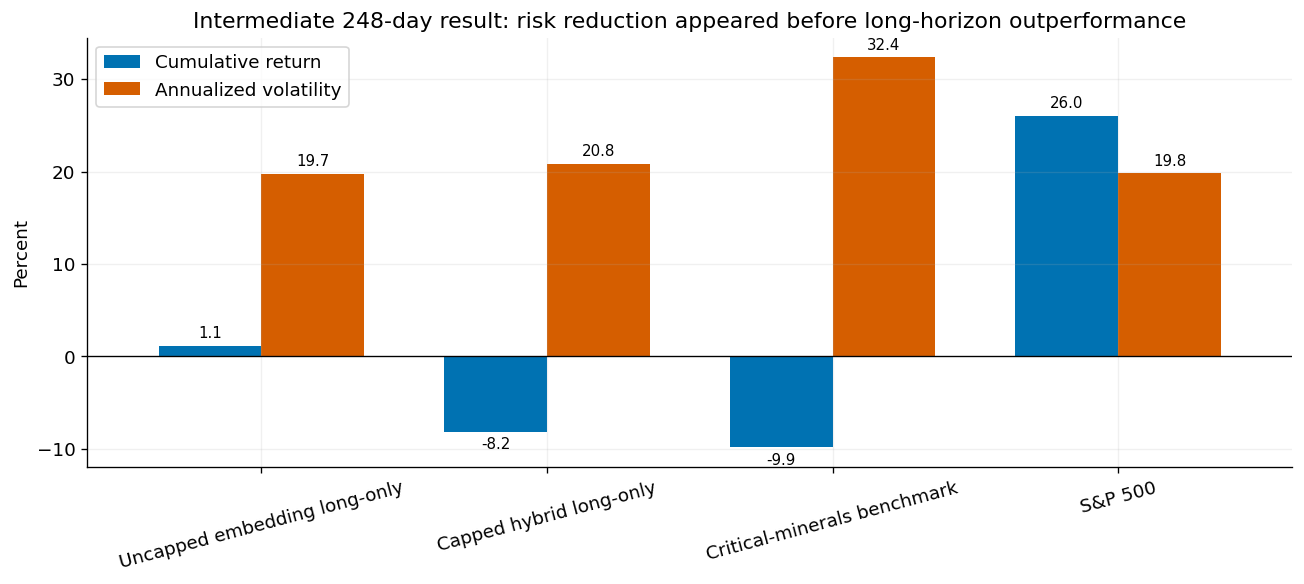

In [5]:
unc=pd.read_parquet(ROOT/'uncapped_seeded_embedding_v1'/'calendar_time_performance_summary.parquet')
cap=pd.read_parquet(ROOT/'capped_portfolio_analysis_v1'/'capped_performance_summary.parquet')
mid=pd.DataFrame([
 {'Portfolio':'Uncapped embedding long-only',**unc[unc.portfolio.eq('long_only')].iloc[0][['cumulative_return','annualized_volatility','maximum_drawdown']].to_dict()},
 {'Portfolio':'Capped hybrid long-only',**cap[cap.portfolio.eq('hybrid_long_only')].iloc[0][['cumulative_return','annualized_volatility','maximum_drawdown']].to_dict()},
 {'Portfolio':'Critical-minerals benchmark',**cap[cap.portfolio.eq('critical_minerals')].iloc[0][['cumulative_return','annualized_volatility','maximum_drawdown']].to_dict()},
 {'Portfolio':'S&P 500',**cap[cap.portfolio.eq('sp500')].iloc[0][['cumulative_return','annualized_volatility','maximum_drawdown']].to_dict()},
])
show=mid.rename(columns={'cumulative_return':'Cumulative return','annualized_volatility':'Annualized volatility','maximum_drawdown':'Maximum drawdown'}).set_index('Portfolio')
display(show.style.format('{:.2%}'))
plot=show[['Cumulative return','Annualized volatility']]*100
ax=plot.plot(kind='bar',figsize=(11,5),color=[BLUE,ORANGE],width=.72);ax.axhline(0,color='black',lw=.8)
ax.set_title('Intermediate 248-day result: risk reduction appeared before long-horizon outperformance')
ax.set_ylabel('Percent');ax.set_xlabel('');ax.tick_params(axis='x',rotation=15);label_bars(ax,'%.1f')
plt.tight_layout();plt.show()

## 10. Final frozen-portfolio persistence test

The final analysis holds the 2024Q1 portfolios from June 2024 through August 2026 without reselection.

- CRSP monthly security returns are used through December 2025.
- Adjusted-price returns extend the surviving securities through August 2026.
- Yahoo reconstruction was validated against CRSP over the overlap.
- Alpha Vantage repaired selected incomplete 2026 histories.
- An acquired or delisted firm contributes its final observed return, then its same-leg weights are redistributed beginning the following month.
- BK is the only surviving firm excluded for missing 2026 coverage. It affects only the uncapped portfolios, begins in January 2026, and is never assigned an artificial zero return.

This is a persistence robustness test, not a new independent formation event.

**Source:** [14G — Persistence Through 2026](14G_2024Q1_Portfolio_Persistence_Through_2026.ipynb).

,Cumulative return,Annualized volatility,Sharpe ratio,Maximum drawdown
Portfolio,,,,
Minerals benchmark,84.84%,32.44%,0.877,-21.80%
Capped hybrid long-only,69.84%,19.46%,1.101,-14.64%
Embedding-only long-only,54.49%,14.06%,1.156,-10.36%
Uncapped embedding long-only,52.86%,14.44%,1.099,-13.73%
S&P 500,49.25%,11.93%,1.216,-7.58%


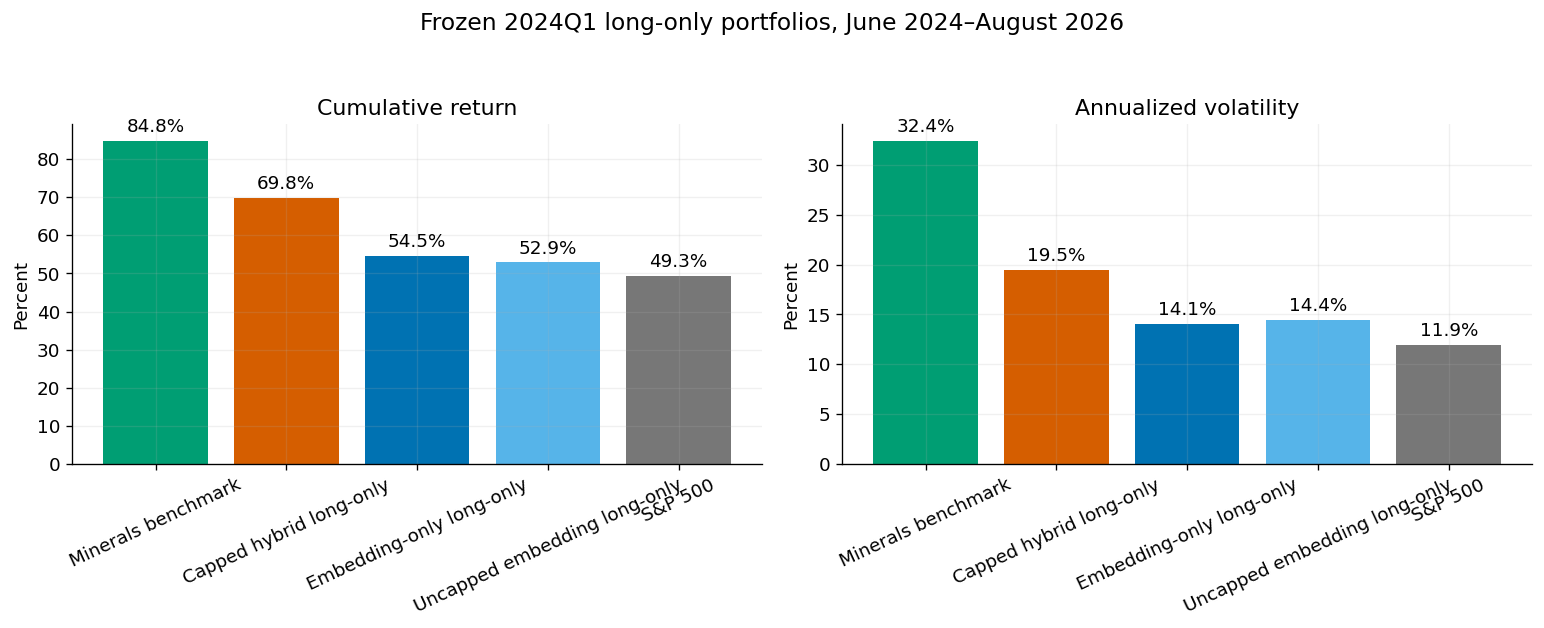

In [6]:
perf=pd.read_parquet(ROOT/'persistence_2024q1_through_2026_v1'/'primary_monthly_performance_bk_excluded.parquet')
names={'critical_minerals':'Minerals benchmark','capped_hybrid_long_only':'Capped hybrid long-only','capped_embedding_only_primary':'Embedding-only long-only','uncapped_long_only':'Uncapped embedding long-only','sp500':'S&P 500'}
final=perf[perf.portfolio.isin(names)].copy();final['Portfolio']=final.portfolio.map(names)
final=final.set_index('Portfolio').loc[list(names.values())]
table=final[['cumulative_return','annualized_volatility','sharpe','maximum_drawdown']].rename(columns={'cumulative_return':'Cumulative return','annualized_volatility':'Annualized volatility','sharpe':'Sharpe ratio','maximum_drawdown':'Maximum drawdown'})
display(table.style.format({'Cumulative return':'{:.2%}','Annualized volatility':'{:.2%}','Sharpe ratio':'{:.3f}','Maximum drawdown':'{:.2%}'}).background_gradient(subset=['Sharpe ratio'],cmap='Blues'))

fig,axes=plt.subplots(1,2,figsize=(13,5));colors=[GREEN,ORANGE,BLUE,SKY,GREY]
bars=axes[0].bar(final.index,final.cumulative_return*100,color=colors);axes[0].set_title('Cumulative return');axes[0].set_ylabel('Percent');axes[0].tick_params(axis='x',rotation=25);axes[0].bar_label(bars,labels=[f'{x:.1f}%' for x in final.cumulative_return*100],padding=3)
bars=axes[1].bar(final.index,final.annualized_volatility*100,color=colors);axes[1].set_title('Annualized volatility');axes[1].set_ylabel('Percent');axes[1].tick_params(axis='x',rotation=25);axes[1].bar_label(bars,labels=[f'{x:.1f}%' for x in final.annualized_volatility*100],padding=3)
fig.suptitle('Frozen 2024Q1 long-only portfolios, June 2024–August 2026',y=1.04,fontsize=14);plt.tight_layout();plt.show()

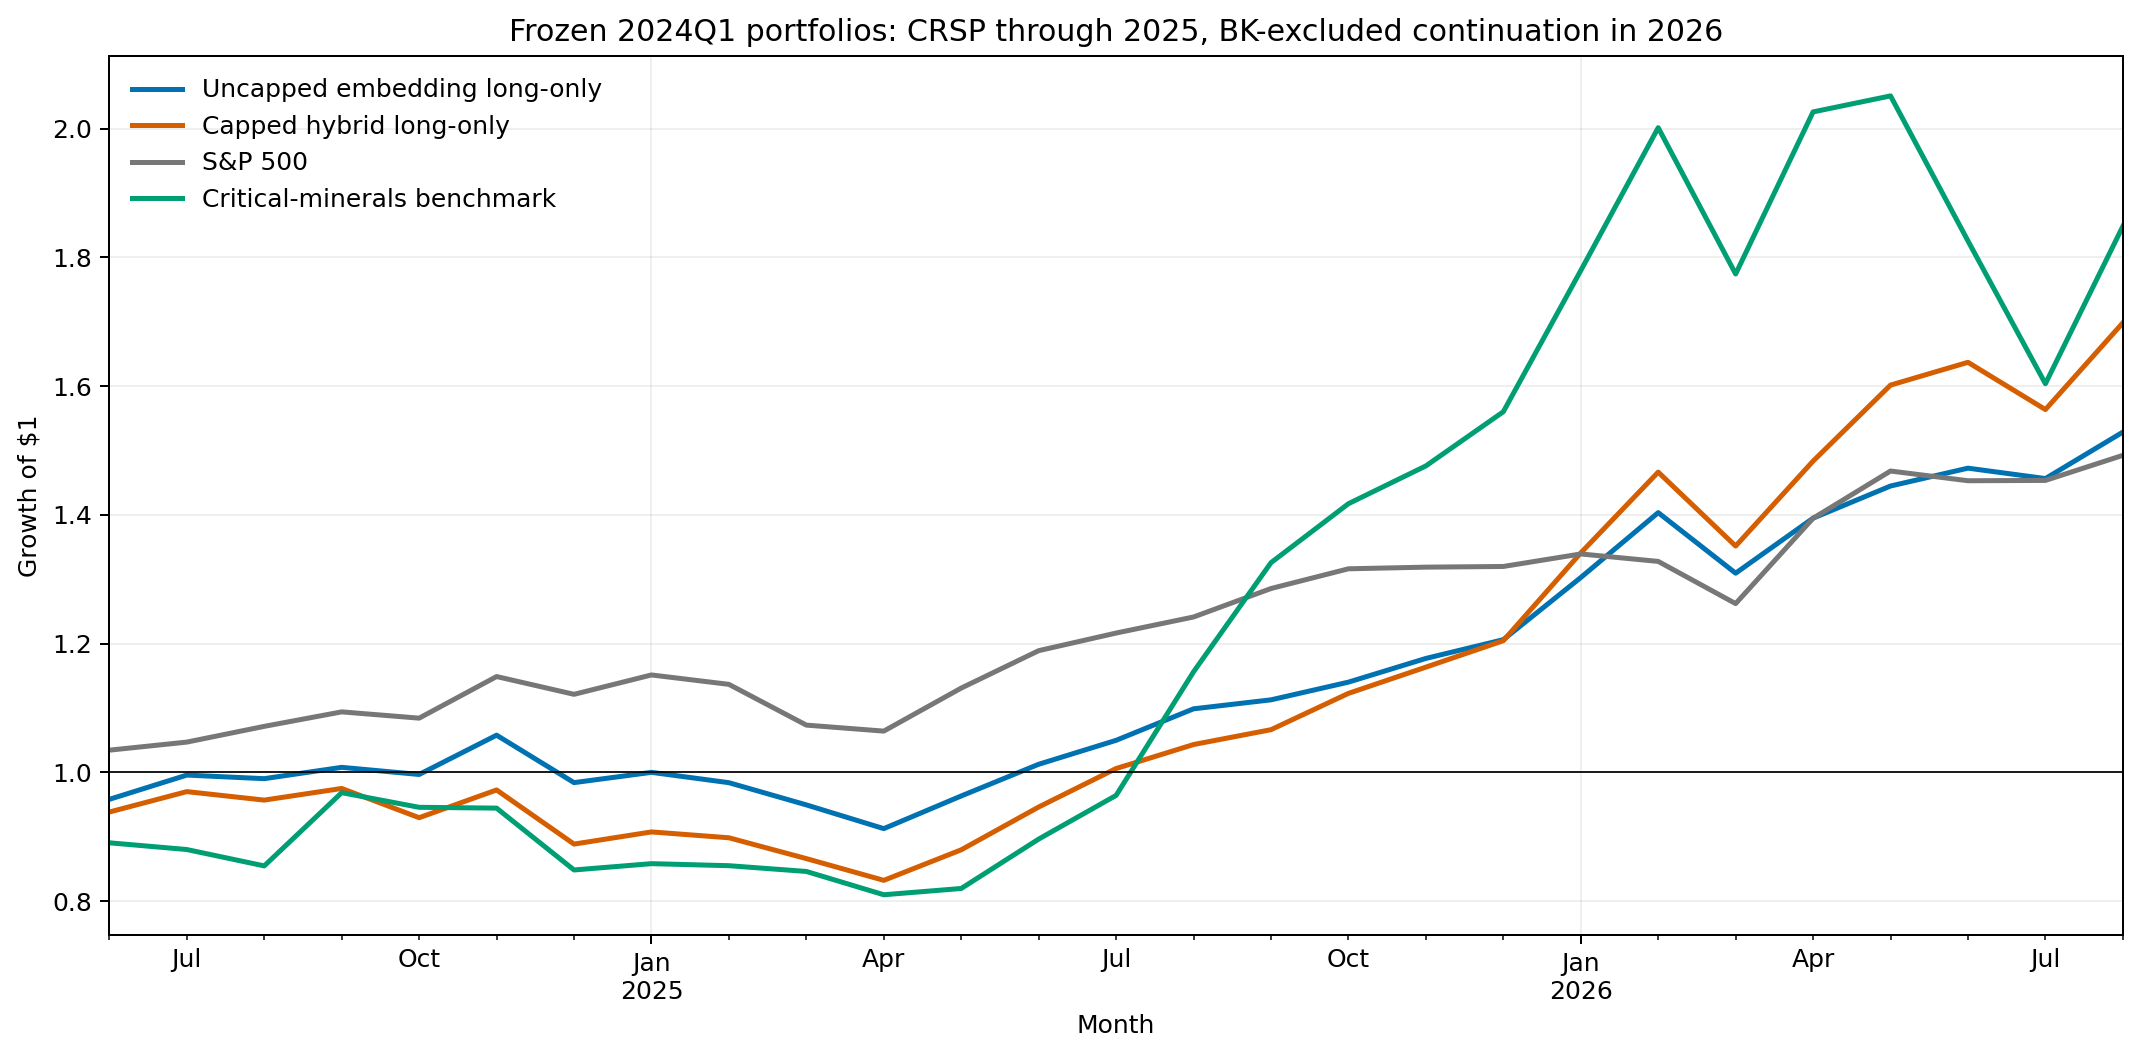

In [7]:
display(Image(filename=str(ROOT/'persistence_2024q1_through_2026_v1'/'figures'/'primary_monthly_persistence_bk_excluded.png')))

### Reading the final long-only result

The minerals benchmark earned the highest raw return, but it also had by far the highest volatility. The capped hybrid earned 69.84% with 19.46% volatility and a 14.64% maximum drawdown. The embedding-only portfolio earned 54.49% with 14.06% volatility and the best thematic-portfolio Sharpe ratio, 1.156.

The uncapped embedding portfolio behaved more like a diversified equity portfolio than a mining index, but it did not lose the theme. This is the core economic result: **embedding expansion exchanged some concentrated upside for a materially smoother thematic exposure.**

## 11. Did diversification erase the critical-minerals theme?

No. Each portfolio was regressed on the market and the critical-minerals benchmark in excess of the market. The critical-minerals coefficient measures incremental thematic sensitivity after controlling for general equity exposure.

,Market beta,Minerals beta,Minerals t-stat,Minerals p-value,Annualized alpha
Portfolio,,,,,
Capped hybrid long-only,0.938,0.364,3.29,0.0010,2.80%
Embedding-only long-only,0.572,0.200,2.35,0.0187,5.25%
Uncapped embedding long-only,0.716,0.245,2.96,0.0031,2.11%
Uncapped long–short,0.081,0.188,4.39,0.0000,0.89%
Beta-neutral long–short,-0.015,0.167,4.59,0.0000,0.07%


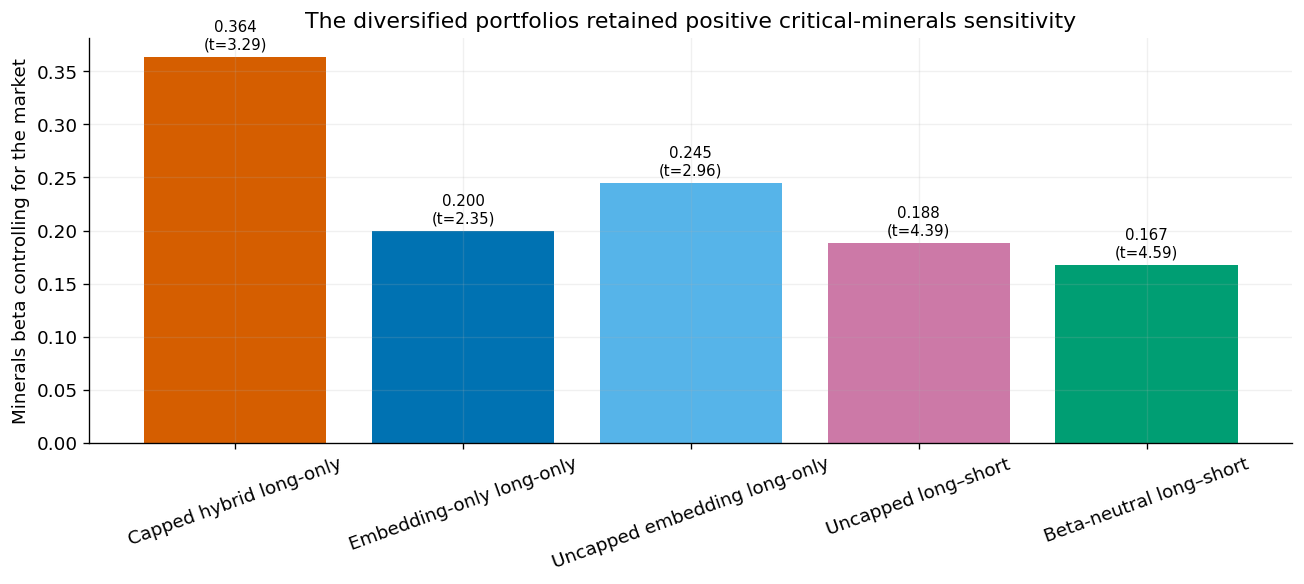

In [8]:
reg=pd.read_parquet(ROOT/'persistence_2024q1_through_2026_v1'/'primary_monthly_theme_regressions_bk_excluded.parquet')
keep=['capped_hybrid_long_only','capped_embedding_only_primary','uncapped_long_only','uncapped_long_short','uncapped_beta_neutral_long_short']
rn={'capped_hybrid_long_only':'Capped hybrid long-only','capped_embedding_only_primary':'Embedding-only long-only','uncapped_long_only':'Uncapped embedding long-only','uncapped_long_short':'Uncapped long–short','uncapped_beta_neutral_long_short':'Beta-neutral long–short'}
r=reg[reg.portfolio.isin(keep)].copy();r['Portfolio']=r.portfolio.map(rn);r=r.set_index('Portfolio').loc[list(rn.values())]
display(r[['market_beta','cm_beta','cm_t','cm_p','annualized_alpha']].rename(columns={'market_beta':'Market beta','cm_beta':'Minerals beta','cm_t':'Minerals t-stat','cm_p':'Minerals p-value','annualized_alpha':'Annualized alpha'}).style.format({'Market beta':'{:.3f}','Minerals beta':'{:.3f}','Minerals t-stat':'{:.2f}','Minerals p-value':'{:.4f}','Annualized alpha':'{:.2%}'}))
fig,ax=plt.subplots(figsize=(11,5));bars=ax.bar(r.index,r.cm_beta,color=[ORANGE,BLUE,SKY,PURPLE,GREEN])
ax.set_title('The diversified portfolios retained positive critical-minerals sensitivity');ax.set_ylabel('Minerals beta controlling for the market');ax.tick_params(axis='x',rotation=20)
ax.bar_label(bars,labels=[f'{b:.3f}\n(t={t:.2f})' for b,t in zip(r.cm_beta,r.cm_t)],padding=3,fontsize=9)
plt.tight_layout();plt.show()

The long-only estimates are statistically significant:

- capped hybrid minerals beta: **0.364**, t = **3.29**;
- embedding-only minerals beta: **0.200**, t = **2.35**; and
- uncapped embedding minerals beta: **0.245**, t = **2.96**.

The beta-neutral long–short portfolio had essentially zero market beta but a positive minerals beta. The holdings-based signal therefore retained thematic structure even after broad-market exposure was substantially removed.

## 12. Long–short portfolios: improvement, but not the main claim

The longer window improved the long–short results relative to the weak initial interval. The capped embedding spread earned 36.87%, the uncapped dollar-neutral spread earned 10.36%, and the beta-neutral spread earned 4.45%.

These figures remain exploratory. They omit full turnover, borrowing, financing, and implementation costs, and they arise from one main formation vintage. The evidence is sufficient to show that the directional embedding structure was not uniformly valueless, but not sufficient to describe a production-ready long–short strategy.

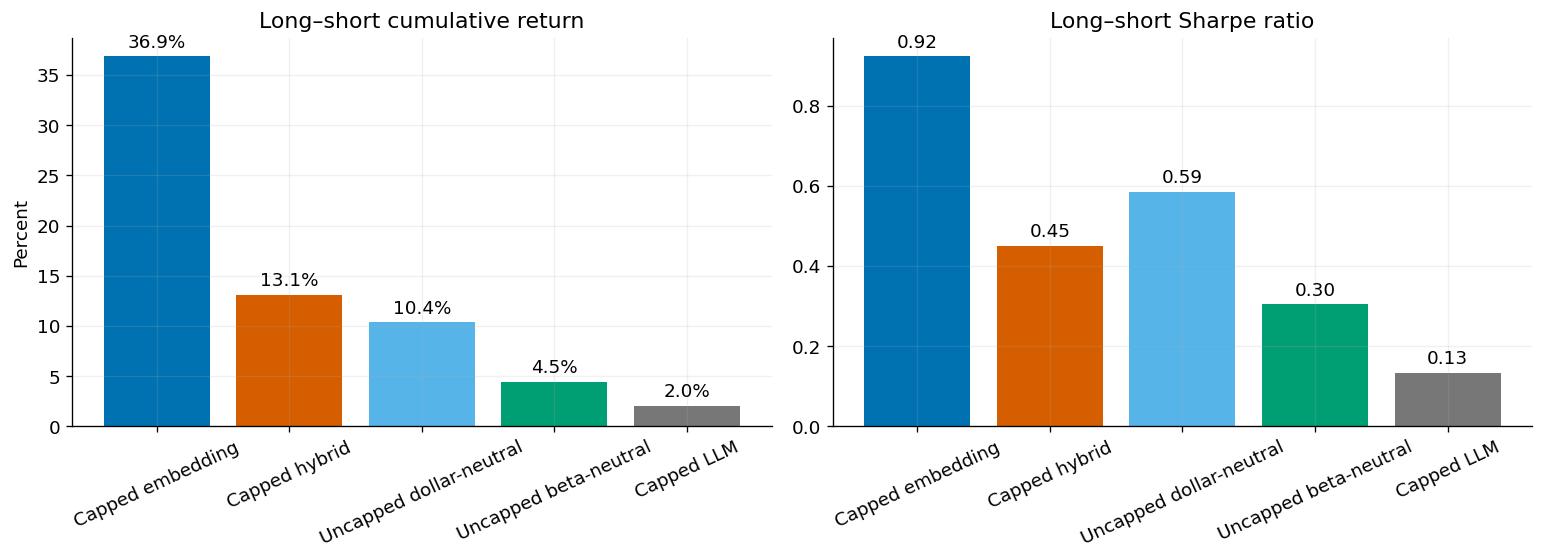

In [9]:
ls_names={'capped_embedding':'Capped embedding','capped_hybrid':'Capped hybrid','uncapped_long_short':'Uncapped dollar-neutral','uncapped_beta_neutral_long_short':'Uncapped beta-neutral','capped_llm':'Capped LLM'}
ls=perf[perf.portfolio.isin(ls_names)].copy();ls['Portfolio']=ls.portfolio.map(ls_names);ls=ls.sort_values('cumulative_return',ascending=False)
fig,axes=plt.subplots(1,2,figsize=(13,4.8));colors=[BLUE,ORANGE,SKY,GREEN,GREY]
bars=axes[0].bar(ls.Portfolio,ls.cumulative_return*100,color=colors);axes[0].set_title('Long–short cumulative return');axes[0].set_ylabel('Percent');axes[0].tick_params(axis='x',rotation=25);axes[0].bar_label(bars,labels=[f'{x:.1f}%' for x in ls.cumulative_return*100],padding=3)
bars=axes[1].bar(ls.Portfolio,ls.sharpe,color=colors);axes[1].set_title('Long–short Sharpe ratio');axes[1].tick_params(axis='x',rotation=25);axes[1].bar_label(bars,labels=[f'{x:.2f}' for x in ls.sharpe],padding=3)
plt.tight_layout();plt.show()

## 13. What the complete project establishes

The evidence supports a specific, bounded conclusion:

> Evidence-grounded LLM analysis can define directional thematic seeds, and holdings-based asset embeddings can propagate those seeds into diversified portfolios that preserve measurable exposure to the original theme.

The strongest evidence concerns **portfolio construction and risk management**:

- the LLM gives an interpretable economic starting point;
- embeddings add a non-textual institutional-ownership channel;
- hybrid and embedding portfolios retain significant minerals exposure;
- broader embedding portfolios reduce volatility and drawdowns relative to the concentrated minerals basket; and
- the strongest thematic portfolios beat the S&P 500 over the completed persistence window, although not the minerals benchmark in raw return.

This is more defensible than claiming that embeddings reliably predict individual firms’ future thematic betas or guarantee abnormal returns.

## 14. Limitations and next validation requirements

1. **One main formation vintage.** The persistence result follows the frozen 2024Q1 portfolio; repeated independent formations are required.
2. **Post-primary horizon extension.** The through-August-2026 analysis was designed after the original short-window outcome was known.
3. **Short regression history.** The final monthly thematic regressions have 27 observations.
4. **Benchmark imperfection.** Equal-weight `COPX`, `LIT`, and `REMX` is investable and relevant but cannot capture every critical-minerals mechanism.
5. **Implementation frictions.** Transaction costs, taxes, market impact, and short-borrow costs are not fully incorporated.
6. **Data-source stitching.** CRSP, Yahoo, and Alpha Vantage were combined under an audited hierarchy. BK was explicitly excluded only for 2026 rather than assigned a fabricated return.
7. **Model dependence.** Labels can vary with the LLM, prompt, passage retrieval, and disclosure quality.
8. **Embedding interpretation.** Co-holding proximity is economic association, not proof of a particular supplier or customer link.

The cleanest next test would repeat the frozen procedure across additional historical formation dates and unrelated economic themes before aggregating any performance evidence.

## 15. Reproducibility map

| Question | Primary notebook |
|---|---|
| How was the point-in-time S&P 500 universe frozen? | [12A](12A_SP500_Point_in_Time_Universe.ipynb) |
| How were filings acquired without opening outcomes? | [12B](12B_SP500_SEC_Corpus.ipynb) |
| How was the prompt calibrated while blinded? | [12C](12C_Blinded_Prompt_Calibration.ipynb) |
| How were production labels generated and validated? | [12D](12D_SP500_Production_Extraction.ipynb), [12D2](12D2_Quarantined_Response_Resolution.ipynb) |
| How were document labels converted to quarterly seeds? | [12E](12E_Quarterly_Exposure_Aggregation.ipynb) |
| How were embeddings propagated and placebo-tested? | [12F](12F_Embedding_Propagation_and_Placebos.ipynb) |
| What happened in the first locked return test? | [12G](12G_Locked_Forward_Performance_Evaluation.ipynb) |
| How were capped hybrid and long–short portfolios defined? | [12H](12H_Long_Short_and_Hybrid_Evaluation.ipynb) |
| Did text and embedding agreement help? | [12I](12I_Text_Embedding_Consensus_Portfolios.ipynb) |
| Did scores predict thematic beta? | [14A](14A_Critical_Minerals_Factor_Construction.ipynb)–[14C](14C_Exposure_Scores_vs_Thematic_Beta.ipynb) |
| Did portfolios retain exposure after factor controls? | [14D](14D_Factor_Controlled_Portfolio_Attribution.ipynb) |
| How were uncapped portfolios generated? | [14E](14E_Uncapped_Seeded_Embedding_Portfolios.ipynb) |
| How were capped and uncapped risks compared? | [14F](14F_Capped_Portfolio_Risk_and_Theme_Analysis.ipynb) |
| How was persistence through August 2026 evaluated? | [14G](14G_2024Q1_Portfolio_Persistence_Through_2026.ipynb) |

Raw SEC filings, WRDS extracts, API response envelopes, and row-level numerical artifacts remain local because of size, licensing, and audit sensitivity. The repository retains the executed notebooks, versioned prompts and schemas, notebook builders, compact design manifests, and presentation figures.

## References and data sources

- Gabaix, Koijen, Richmond, and Yogo, *Asset Embeddings*, July 2026 working-paper version included in the project repository.
- U.S. Securities and Exchange Commission, [EDGAR filings](https://www.sec.gov/edgar/search/).
- CRSP and Compustat data accessed through [Wharton Research Data Services](https://wrds-www.wharton.upenn.edu/).
- Kenneth R. French Data Library, daily Fama–French factors and momentum factor.
- Critical-minerals benchmark: equal-weight daily returns of `COPX`, `LIT`, and `REMX`.
- Extended adjusted-price robustness data: Yahoo Finance and Alpha Vantage, subject to the source and coverage audits recorded in Notebook 14G.

All performance results are research diagnostics and not investment advice.